# Week 6 - Task B: three charts, three different questions

All three read the cleaned files that `partA_process.py` writes to `clean/`, so run Task A first.

| Chart | Kind of question | File | Decision it supports |
|---|---|---|---|
| B1 | **Trend** | `grid_daily_clean.csv` | how much supply to plan for next summer, zone by zone |
| B2 | **Composition** (part-to-whole) | `generation_parts.csv` | which solar line the communications office can honestly use |
| B3 | **Relationship** | `district_grid_clean.csv` | whether rooftop solar can be sold as help for the poorer districts |

All data is synthetic course data for CDB601220 (Week 6).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

try:
    HERE = Path(__file__).resolve().parent
    IN_NOTEBOOK = False
except NameError:
    HERE = Path.cwd() / "submission"
    IN_NOTEBOOK = True


def find_root(start):
    for cand in (start.parent, start, start.parent / "assignments", start / "assignments"):
        if (cand / "data" / "district_grid.csv").exists() and (cand / "tslib.py").exists():
            return cand
    raise SystemExit("Can't find data/ and the toolkits. Put this folder next to them (see README).")


ROOT = find_root(HERE)
sys.path.insert(0, str(ROOT))


def show():
    """Inline in the notebook; as a script just close the figure (the PNG is already saved)."""
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close("all")


import vizlib as vz
from vizlib import PALETTE, save_fig, style_defaults

CLEAN = HERE / "clean"
if not (CLEAN / "grid_daily_clean.csv").exists():
    raise SystemExit("clean/ is empty: run partA_process.py first")
CHARTS = ROOT / "charts"
if IN_NOTEBOOK:
    CHARTS.mkdir(exist_ok=True)
style_defaults()
BLUE, ORANGE, GREEN = PALETTE["series"]
GREY, INK, SOFT = PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]
SRC = "Source: synthetic course data, CDB601220 Week 6 ({}), cleaned by partA_process.py. Chart: Syed Sami Ullah."


def export(fig, name, note):
    path = save_fig(fig, HERE / name, note=note)
    if IN_NOTEBOOK:
        fig.savefig(CHARTS / name, dpi=300, bbox_inches="tight", facecolor=PALETTE["surface"])
    return path

## B1 · Trend: daily energy delivered, six zones

**Parameters, decided before drawing.** Energy is the day-to-day change in the meter (Task A rule 14), never the reading itself. Each zone gets its own panel on the full 529-day calendar, so an unreported day is a break in the line and an orange tick under it. The smoother is a **28-day centred mean**, needing at least 21 real days in the window; it averages only the days that exist and never treats a gap as zero. 28 days because it removes the day-to-day noise but keeps the seasonal turn (the window report below shows the daily wobble is small next to the season: 28 days removes 4.4% of the variation, while 91 days removes 11.2% because it starts flattening the summer peak itself and loses 45 days at each end; 7 and 28 look almost the same here, and 28 is calmer to read). The year-on-year number compares the **mean MWh per reported day** for June-August, because a straight `sum()` over a period with gaps punishes the zone that missed more days.

In [2]:
day = pd.read_csv(CLEAN / "grid_daily_clean.csv", parse_dates=["date"])
miss = pd.read_csv(CLEAN / "grid_daily_unreported.csv", parse_dates=["date"])
span = pd.date_range(day.date.min(), day.date.max(), freq="D")
E = day.pivot(index="date", columns="zone", values="energy_mwh").reindex(span)
ZONES = list(E.columns)

import tslib as tl
print("window report for P6 (the biggest zone), MWh/day:")
print(tl.window_report(E["P6"], (7, 28, 91)).to_string(index=False))

roll = E.rolling(28, center=True, min_periods=21).mean()
s25 = E["2025-06-01":"2025-08-31"]
s26 = E["2026-06-01":"2026-08-31"]
yoy = (s26.mean() / s25.mean() - 1) * 100
naive = (s26.sum() / s25.sum() - 1) * 100
print("\nsummer (Jun-Aug) mean MWh per reported day, 2026 vs 2025:")
print(pd.DataFrame({"days 2025": s25.notna().sum(), "days 2026": s26.notna().sum(), "mean-per-day change %": yoy.round(1),
                    "sum() change % (wrong)": naive.round(1)}).to_string())
print(f"\nvalid daily energy values plotted: {int(E.notna().sum().sum()):,}; empty days (unreported, the day before a gap, the meter swap, the last day): {int(E.isna().sum().sum())}")

window report for P6 (the biggest zone), MWh/day:
 window     raw_sd  smoothed_sd  variation_removed_pct  periods_lost_each_end
      7 20179.9634   19468.1012                    3.5                      3
     28 20179.9634   19283.2598                    4.4                     14
     91 20179.9634   17915.4951                   11.2                     45

summer (Jun-Aug) mean MWh per reported day, 2026 vs 2025:
      days 2025  days 2026  mean-per-day change %  sum() change % (wrong)
zone                                                                     
P1           92         86                    6.1                    -0.8
P2           82         76                    6.8                    -1.1
P3           86         86                    6.5                     6.5
P4           82         80                    7.5                     4.9
P5           83         84                    5.9                     7.1
P6           88         86                    6.3            

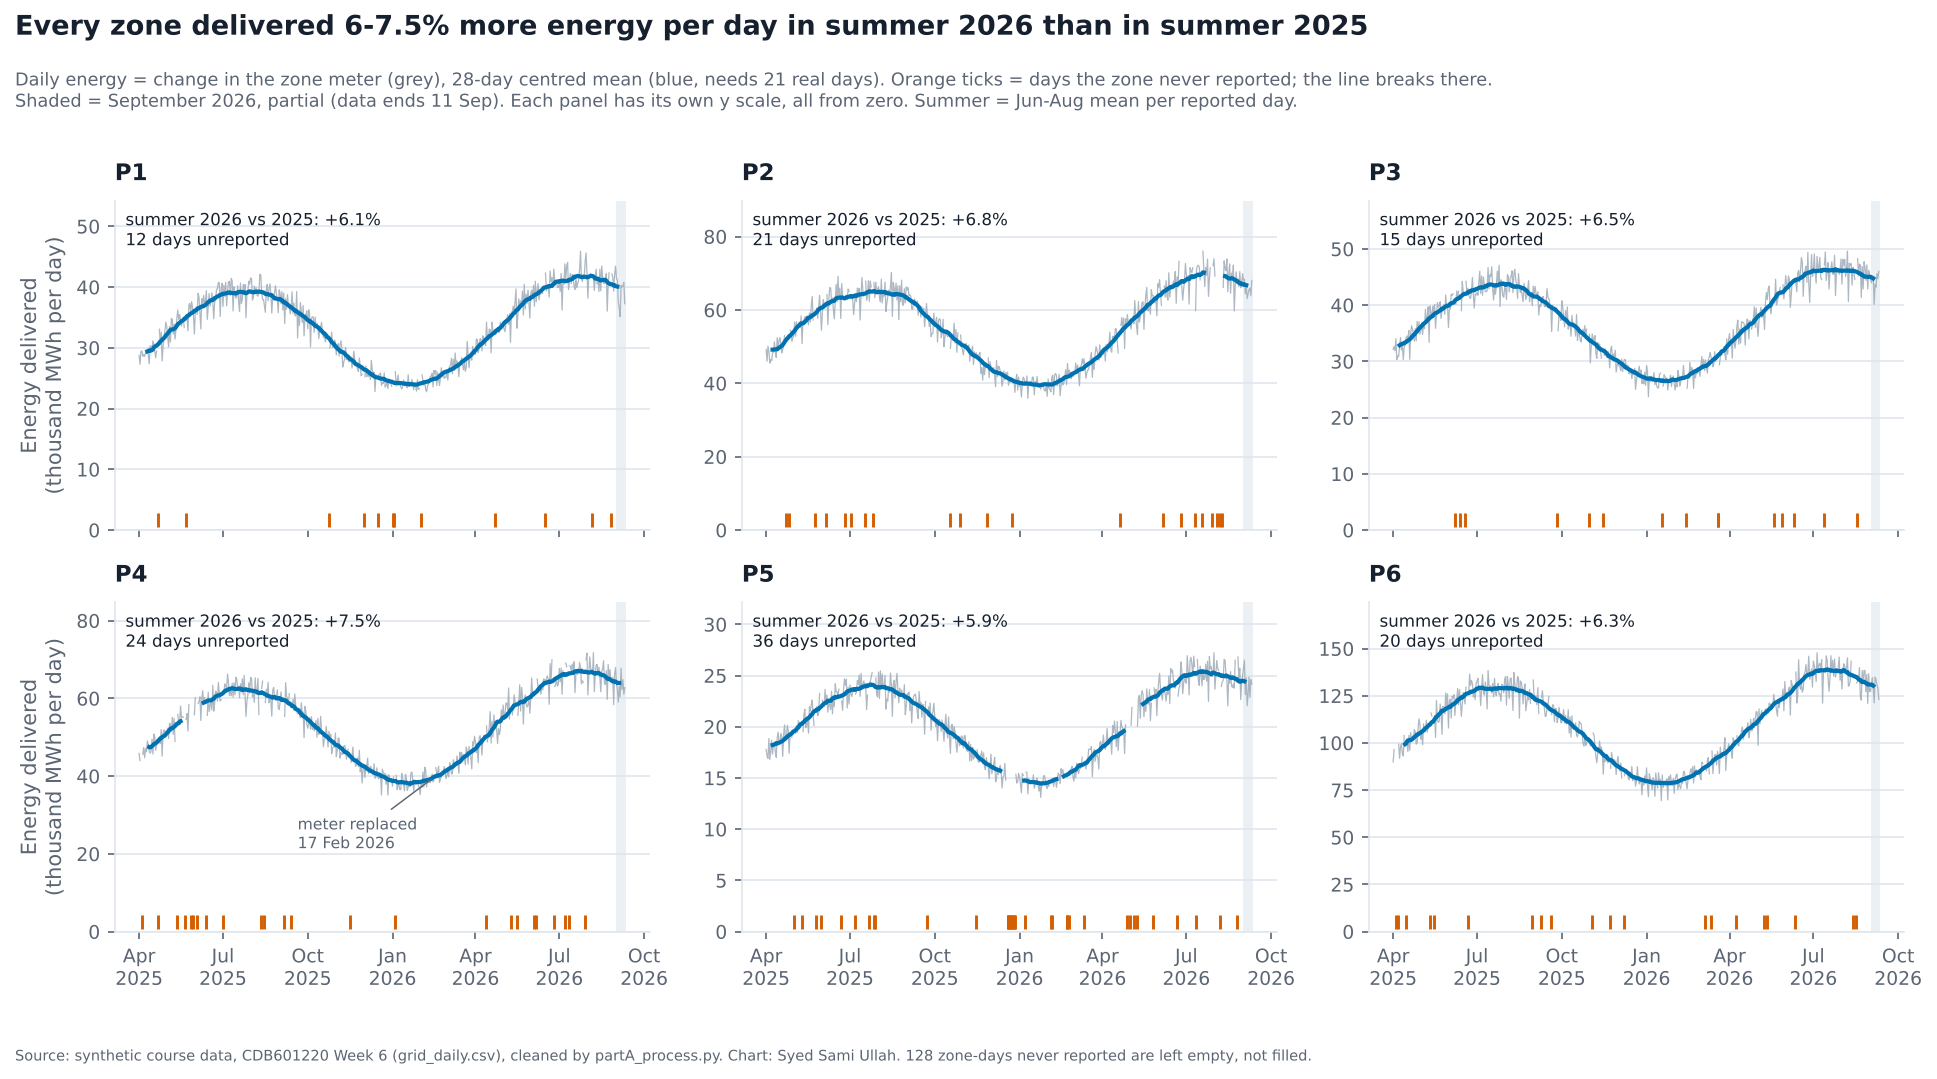

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.8), sharex=True)
for ax, z in zip(axes.flat, ZONES):
    ax.plot(E.index, E[z] / 1000, color=GREY, lw=0.6, alpha=0.8)
    ax.plot(roll.index, roll[z] / 1000, color=BLUE, lw=2)
    top = np.nanmax(E[z].to_numpy()) / 1000 * 1.18
    ax.set_ylim(0, top)
    mz = miss[miss.zone == z].date
    ax.plot(mz, np.full(len(mz), top * 0.03), "|", color=ORANGE, ms=7, mew=1.4)
    ax.set_title(f"{z}", loc="left", fontsize=11)
    ax.text(0.02, 0.97, f"summer 2026 vs 2025: {yoy[z]:+.1f}%\n{len(mz)} days unreported",
            transform=ax.transAxes, va="top", fontsize=8, color=INK)
    ax.axvspan(pd.Timestamp("2026-09-01"), span[-1], color=PALETTE["grid"], alpha=0.6, lw=0)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.grid(axis="x", visible=False)
for ax in axes[:, 0]:
    ax.set_ylabel("Energy delivered\n(thousand MWh per day)")
p4 = axes.flat[ZONES.index("P4")]
p4.annotate("meter replaced\n17 Feb 2026", xy=(pd.Timestamp("2026-02-16"), roll["P4"]["2026-02-16"] / 1000),
            xytext=(pd.Timestamp("2025-09-20"), roll["P4"].max() / 1000 * 0.32), fontsize=7.5, color=SOFT,
            arrowprops=dict(arrowstyle="-", color=SOFT, lw=0.7))
fig.suptitle(f"Every zone delivered {yoy.min():.0f}-{yoy.max():.1f}% more energy per day in summer 2026 than in summer 2025",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.925, "Daily energy = change in the zone meter (grey), 28-day centred mean (blue, needs 21 real days). Orange ticks = days the zone never reported; "
         "the line breaks there.\nShaded = September 2026, partial (data ends 11 Sep). Each panel has its own y scale, all from zero. Summer = Jun-Aug mean per reported day.",
         fontsize=8.5, color=SOFT, va="top")
fig.tight_layout(rect=(0, 0, 1, 0.905))
export(fig, "partB_1.png", SRC.format("grid_daily.csv") + " 128 zone-days never reported are left empty, not filled.")
show()

**What this chart shows.** All six zones follow the same summer peak and winter dip, and in every zone summer 2026 sat 5.9-7.5% above summer 2025 (P4 highest). The orange ticks show the missing days are not spread evenly: P5 lost 36, P1 only 12.

**Decision it supports:** plan summer-2027 supply on roughly 6-7% growth in every zone, not on last summer's level. (Summing the days instead of averaging them would have shown P1 and P2 *falling*, just because they missed more summer days.)

## B2 · Composition: what the energy was generated from

**Parameters.** The 8 part rows only (the ministry's Total row was moved out in Task A, rule 17). Bars are absolute **TWh per month** from zero, not 100% bars, so the reader sees the total fall while the solar slice grows. Solar sits at the bottom so it shares the baseline and its height can be read. The other categories are grouped to their top level (Fossil = gas + coal + furnace oil, Hydro = dam + run-of-river) and kept grey, because the question is only about solar. All 18 months are complete.

In [4]:
parts = pd.read_csv(CLEAN / "generation_parts.csv")
parts["group"] = np.where(parts.subsource.isin(["Solar", "Wind"]), parts.subsource, parts.source)
wide = parts.pivot_table(index="month", columns="group", values="mwh", aggfunc="sum") / 1e6
ORDER = ["Solar", "Wind", "Hydro", "Imported", "Fossil"]
wide = wide[ORDER]
total = wide.sum(axis=1)
sol = wide["Solar"]
share = sol / total * 100
g_chg, s_chg = total.iloc[-1] / total.iloc[0] - 1, sol.iloc[-1] / sol.iloc[0] - 1
flat_share = sol.iloc[0] / total.iloc[-1] * 100
same_month = {m: sol[f"2026-{m}"] / sol[f"2025-{m}"] - 1 for m in ["04", "05", "06", "07", "08", "09"]}
print(f"total {total.index[0]} -> {total.index[-1]}: {total.iloc[0]:.2f} -> {total.iloc[-1]:.2f} TWh ({g_chg * 100:+.1f}%)")
print(f"solar: {sol.iloc[0]:.3f} -> {sol.iloc[-1]:.3f} TWh ({s_chg * 100:+.1f}%), share {share.iloc[0]:.1f}% -> {share.iloc[-1]:.1f}%")
print(f"if solar had stayed at its April-2025 MWh, the falling total alone would move its share to {flat_share:.2f}% "
      f"-> {flat_share - share.iloc[0]:.2f} of the {share.iloc[-1] - share.iloc[0]:.2f} points are arithmetic")
print("same month a year apart, solar MWh: " + ", ".join(f"{m}: {v * 100:+.0f}%" for m, v in same_month.items()))
assert round(g_chg * 100, 1) == -5.0 and round(s_chg * 100, 1) == 82.1
assert round(share.iloc[0], 1) == 4.1 and round(share.iloc[-1], 1) == 7.9

total 2025-04 -> 2026-09: 11.05 -> 10.49 TWh (-5.0%)
solar: 0.458 -> 0.833 TWh (+82.1%), share 4.1% -> 7.9%
if solar had stayed at its April-2025 MWh, the falling total alone would move its share to 4.36% -> 0.22 of the 3.80 points are arithmetic
same month a year apart, solar MWh: 04: +48%, 05: +62%, 06: +48%, 07: +36%, 08: +35%, 09: +35%


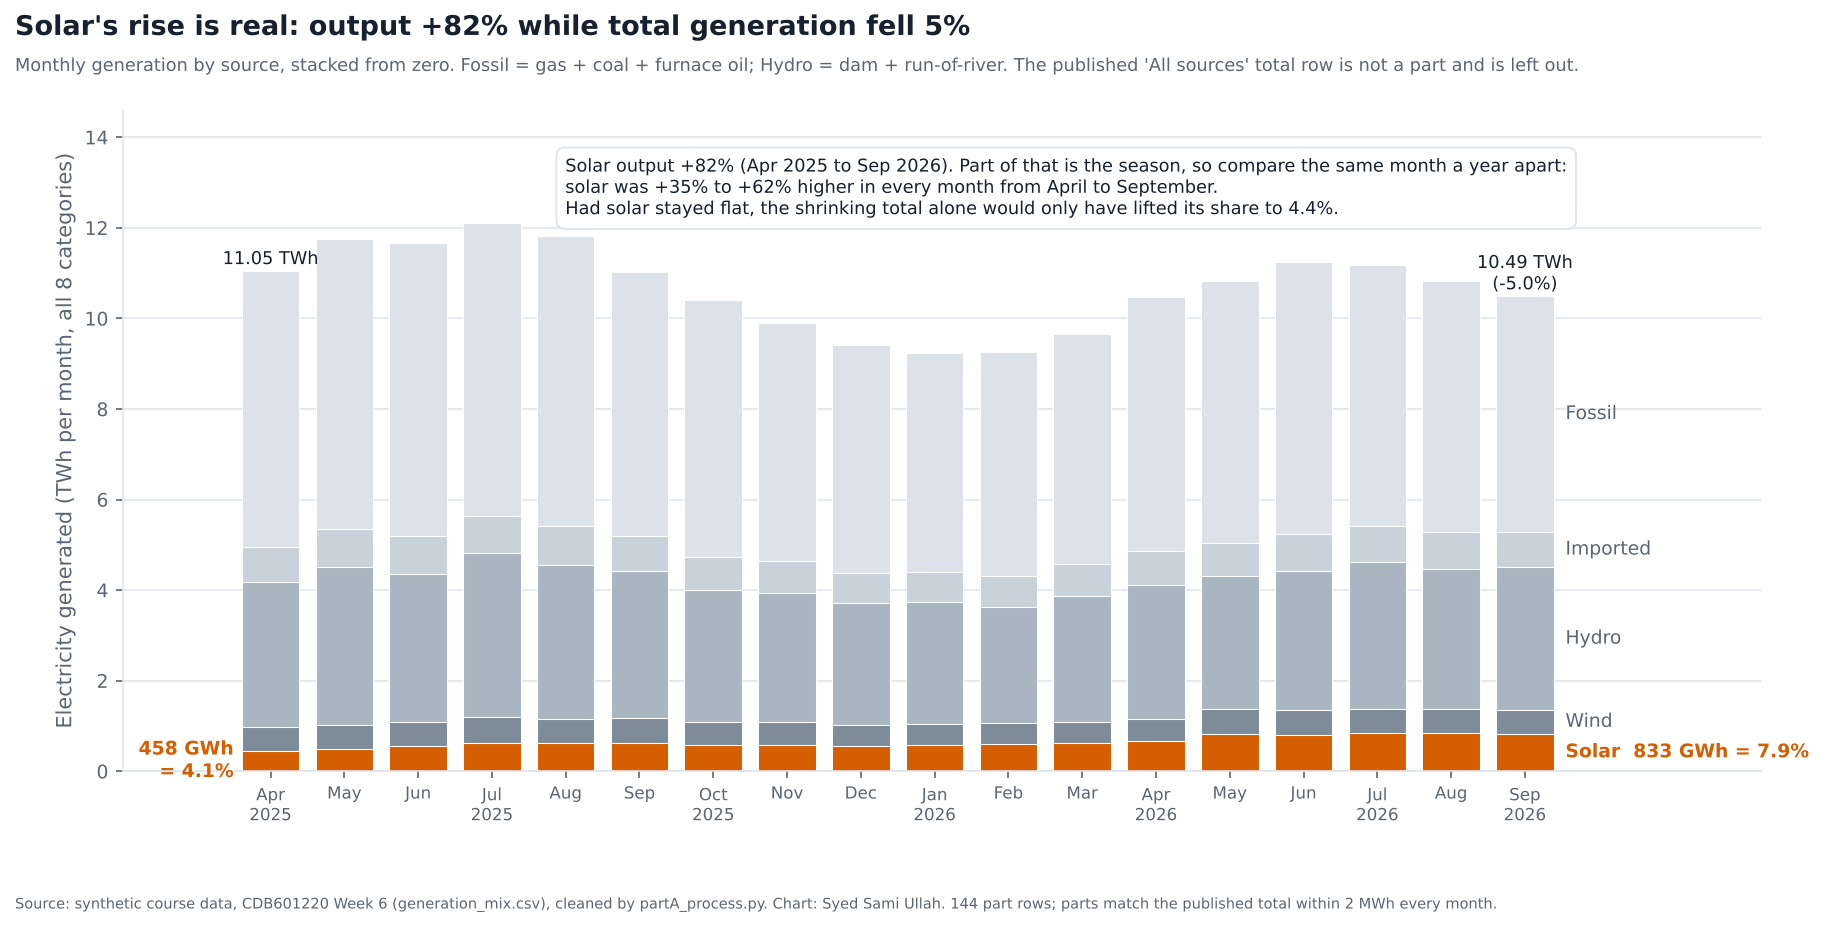

In [5]:
COL = {"Solar": ORANGE, "Wind": "#7E8C9A", "Hydro": "#A9B5C1", "Imported": "#C9D2DB", "Fossil": "#DCE2E8"}
x = np.arange(len(wide))
fig, ax = plt.subplots(figsize=(12, 5.8))
bottom = np.zeros(len(wide))
for g in ORDER:
    ax.bar(x, wide[g], bottom=bottom, color=COL[g], width=0.78, edgecolor="white", linewidth=0.5)
    if g != "Solar":
        ax.text(x[-1] + 0.55, bottom[-1] + wide[g].iloc[-1] / 2, g, va="center", fontsize=9, color=SOFT)
    bottom += wide[g].to_numpy()
ax.text(x[-1] + 0.55, sol.iloc[-1] / 2, f"Solar  {sol.iloc[-1] * 1000:.0f} GWh = {share.iloc[-1]:.1f}%", va="center",
        fontsize=9, color=ORANGE, fontweight="bold")
ax.text(x[0] - 0.5, sol.iloc[0] / 2, f"{sol.iloc[0] * 1000:.0f} GWh\n= {share.iloc[0]:.1f}%", va="center", ha="right",
        fontsize=9, color=ORANGE, fontweight="bold")
ax.text(x[0], total.iloc[0] + 0.15, f"{total.iloc[0]:.2f} TWh", ha="center", fontsize=8.5, color=INK)
ax.text(x[-1], total.iloc[-1] + 0.15, f"{total.iloc[-1]:.2f} TWh\n({g_chg * 100:+.1f}%)", ha="center", fontsize=8.5, color=INK)
ax.text(0.27, 0.93,
        f"Solar output {s_chg * 100:+.0f}% (Apr 2025 to Sep 2026). Part of that is the season, so compare the same month a year apart:\n"
        f"solar was {min(same_month.values()) * 100:+.0f}% to {max(same_month.values()) * 100:+.0f}% higher in every month from April to September.\n"
        f"Had solar stayed flat, the shrinking total alone would only have lifted its share to {flat_share:.1f}%.",
        transform=ax.transAxes, fontsize=8.5, color=INK, va="top",
        bbox=dict(boxstyle="round,pad=0.5", fc="white", ec=PALETTE["grid"]))
ax.set_xticks(x)
ax.set_xticklabels([pd.Period(m).strftime("%b\n%Y") if (i % 3 == 0 or i == len(x) - 1) else pd.Period(m).strftime("%b")
                    for i, m in enumerate(wide.index)], fontsize=8)
ax.set_xlim(-2.0, len(x) + 2.2)
ax.set_ylim(0, 14.6)
ax.set_ylabel("Electricity generated (TWh per month, all 8 categories)")
ax.grid(axis="x", visible=False)
fig.suptitle(f"Solar's rise is real: output {s_chg * 100:+.0f}% while total generation fell {abs(g_chg) * 100:.0f}%",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.915, "Monthly generation by source, stacked from zero. Fossil = gas + coal + furnace oil; Hydro = dam + run-of-river. "
         "The published 'All sources' total row is not a part and is left out.", fontsize=8.5, color=SOFT)
fig.subplots_adjust(top=0.87, left=0.07, right=0.98)
export(fig, "partB_2.png", SRC.format("generation_mix.csv") + " 144 part rows; parts match the published total within 2 MWh every month.")
show()

**What this chart shows.** Total generation dipped through the winter and ended 5% below where it started, while the orange solar slice kept growing, from 458 to 833 GWh a month. Same month against same month, solar was up 35-62%, so the growth is not just the season or a shrinking total.

**Decision it supports:** the communications office can say "solar output was 35-62% higher than in the same month a year earlier" and give the share (4.1% to 7.9%) together with the fact that total generation fell. Only about 0.2 of the 3.8 share points is arithmetic.

## B3 · Relationship: rooftop solar against income, 24 districts

**Parameters.** Solar is put **per billed household** (kW installed / households), because a raw kW total just ranks districts by size. This uses the repaired D21 household count: with the raw 182 households D21 would have shown about 1,357 kW per household and flattened every other point. Income is USD per person per year, on a linear axis from the data's range. All 24 districts, nothing excluded. One colour; the labels are only on the four districts the text talks about.

In [6]:
reg = pd.read_csv(CLEAN / "district_grid_clean.csv")
reg["solar_kw_per_hh"] = reg.solar_kw_installed / reg.households
r = reg.solar_kw_per_hh.corr(reg.income_pc_usd)
slope, icpt = np.polyfit(reg.income_pc_usd, reg.solar_kw_per_hh, 1)
raw_d21 = reg.loc[reg.code == "D21", "solar_kw_installed"].iloc[0] / 182
print(f"r(solar kW per household, income per head) = {r:+.3f}, n = {len(reg)}; slope {slope * 1000:.2f} kW per household per $1,000")
print(f"D21 with the raw 182 households would be {raw_d21:,.0f} kW per household")
print(reg.sort_values("income_pc_usd")[["code", "district", "income_pc_usd", "solar_kw_per_hh"]].round(2).to_string(index=False))

r(solar kW per household, income per head) = +0.930, n = 24; slope 0.25 kW per household per $1,000
D21 with the raw 182 households would be 1,357 kW per household
code      district  income_pc_usd  solar_kw_per_hh
 D13      Mehrabad           2600             0.19
 D22      Virkabad           2600             0.48
 D18   Rohtas West           4450             1.08
 D12       Lashkar           4500             0.97
 D24       Zhobara           5050             0.66
 D08 Haripur North           5300             1.09
 D20        Tarmak           5500             0.79
 D11         Kotla           5950             1.17
 D10       Jandran           5950             1.43
 D21        Ushkan           6100             1.36
 D19    Sibbi East           6200             1.49
 D07        Gulrez           6200             1.14
 D03        Chakwa           6700             1.52
 D01        Ashkan           6900             1.33
 D14      Nawabsar           6950             1.07
 D16      Panjgora  

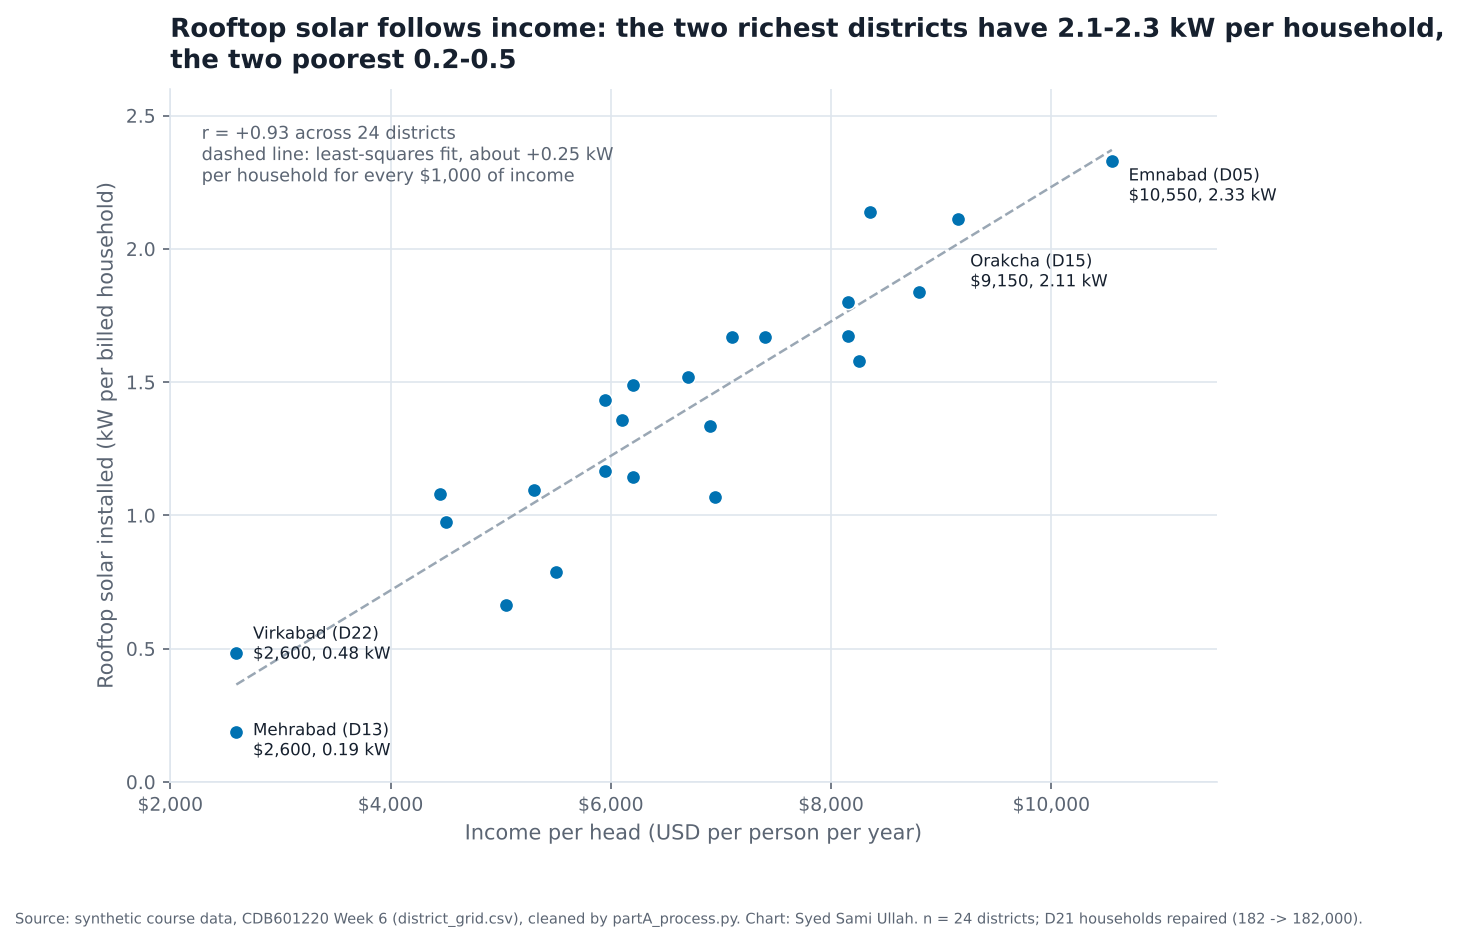

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
xx = np.linspace(reg.income_pc_usd.min(), reg.income_pc_usd.max(), 50)
ax.plot(xx, icpt + slope * xx, color=GREY, lw=1.2, ls="--", zorder=1)
ax.scatter(reg.income_pc_usd, reg.solar_kw_per_hh, s=46, color=BLUE, edgecolor="white", linewidth=0.7, zorder=3)
LAB = {"D05": (8, -12), "D15": (6, -16), "D13": (8, -4), "D22": (8, 4)}
for code, (dx, dy) in LAB.items():
    rr = reg[reg.code == code].iloc[0]
    ax.annotate(f"{rr.district} ({code})\n${rr.income_pc_usd:,}, {rr.solar_kw_per_hh:.2f} kW",
                (rr.income_pc_usd, rr.solar_kw_per_hh), xytext=(dx, dy), textcoords="offset points",
                fontsize=8, color=INK, ha="left" if dx > 0 else "right", va="top" if dy < -14 else "center")
ax.text(0.03, 0.95, f"r = {r:+.2f} across 24 districts\ndashed line: least-squares fit, about +{slope * 1000:.2f} kW\nper household for every $1,000 of income",
        transform=ax.transAxes, fontsize=8.5, color=SOFT, va="top")
ax.set_ylim(0, 2.6)
ax.set_xlim(2000, 11500)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_xlabel("Income per head (USD per person per year)")
ax.set_ylabel("Rooftop solar installed (kW per billed household)")
ax.set_title("Rooftop solar follows income: the two richest districts have 2.1-2.3 kW per household,\nthe two poorest 0.2-0.5", fontsize=12.5)
export(fig, "partB_3.png", SRC.format("district_grid.csv") + " n = 24 districts; D21 households repaired (182 -> 182,000).")
show()

In [8]:
used = [BLUE, ORANGE, GREY]
vz.cvd_report(used, "deutan")
i, j, a, b, d = vz.worst_pair([BLUE, ORANGE], "deutan")
print(f"blue vs orange under deuteranopia: dE {d:.1f} -> {vz.verdict(d)}")

deutan simulation
  #0072B2  ->  #3B67B1
  #D55E00  ->  #9E8C00
  #9AA7B4  ->  #9FA4B4
blue vs orange under deuteranopia: dE 28.1 -> clear


**What this chart shows.** The points climb almost in a straight line (r = +0.93): Emnabad and Orakcha, the two richest districts, have about 2.1-2.3 kW per household, while Mehrabad and Virkabad ($2,600 a head) have 0.19 and 0.48.

**Decision it supports:** the solar line should not suggest rooftop solar is easing things for the poorer districts. It is concentrated where incomes are high, and Mehrabad (D13), one of the worst-served districts in Task C, has the least of it.